# Relatório

Este trabalho foi desenvolvido sobre uma amostra de dados do Cadastro Único para Programas Sociais do Governo Federal (CadÚnico) referente ao ano de 2018, e tem como objetivo analisar possíveis correlações entre diferentes aspectos sociais.

### Pergunta 1 - Desigualdade de renda e interseccionalidade (Renda x Gênero x Cor/Raça)


Conforme observado nos gráficos abaixo, quando comparados indivíduos de mesma cor/raça e sexos distintos, homens apresentam uma renda média e mediana expressivamente superiores às das mulheres em todos os casos analisados. Com relação à indivíduos de diferentes cores/raças, notou-se também significativas diferenças, onde, em uma extremidade temos o homem branco (líder em média e mediana de renda), com uma renda média de R\$ 798,27 (mediana de R\$ 700), enquanto na outra, a mulher indígena, com uma renda média de R\$ 347,98 (mediana de R\$200), cerca de 2.3x menos do que a média de um homem branco.
Vale ainda observar que a posição relativa entre grupos de indivíduos de mesmo sexo, mas cores/raças diferentes se preserva em ambos os sexos, mantendo a seguinte ordem: Branca -> Amarela -> Preta -> Parda -> Indígena, da maior renda média/mediana pra menor, respectivamente. O comportamento observado é condizente com as disparidades salariais entre grupos raciais e de gênero frequentemente documentadas na sociedade brasileira. Isso é um reflexo de séculos de exclusão desses grupos, cujas consequências persistem ainda hoje no mercado de trabalho, como pode-se observar abaixo.

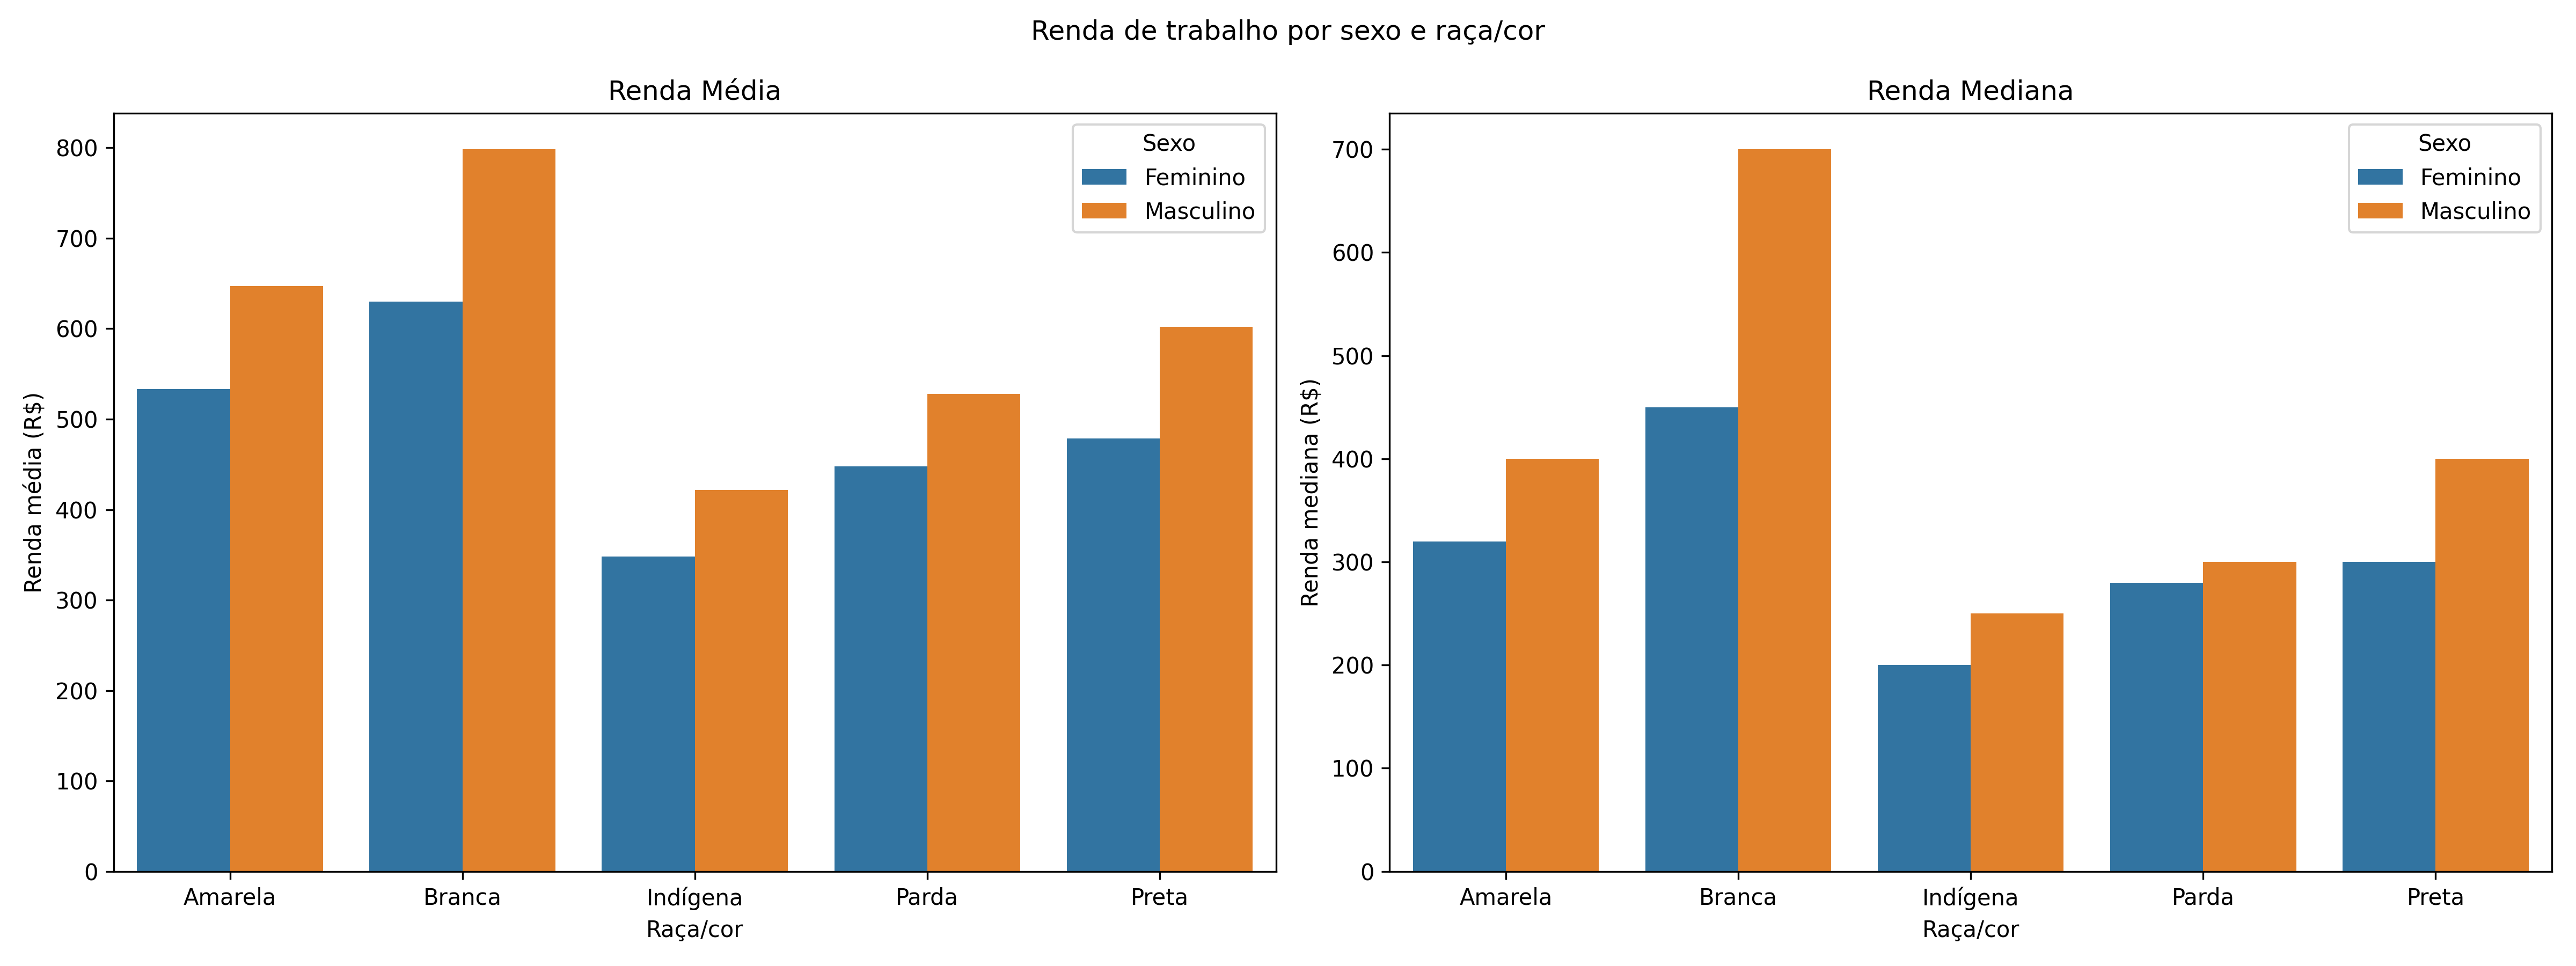

### Pergunta 2 - Relação entre nível de escolaridade e trabalho informal

Agrupando os indivíduos em 4 grupos por grau de instrução (Ensino Fundamental, Ensino Médio, Ensino Superior e Sem Escolaridade), constatou-se que aqueles com formação superior possuem a maior taxa de informalidade de emprego, com 7,75%, seguidos daqueles que concluíram o ensino médio, com 7,14%. Em seguida, está o grupo de pessoas com ensino fundamental completo, com 5,83%, e, por fim, o grupo de indivíduos sem escolaridade, com a menor taxa de emprego informal dentre todos os conjuntos analisados, com apenas 4,60%. Essa análise sugere uma possível correlação positiva, onde, quanto maior o nível de escolaridade, maior é a taxa de informalidade do trabalho, o que é totalmente contra-intuitivo, haja visto que os estudos são retratados em nossa sociedade frequentemente como uma fuga aos trabalhos informais.

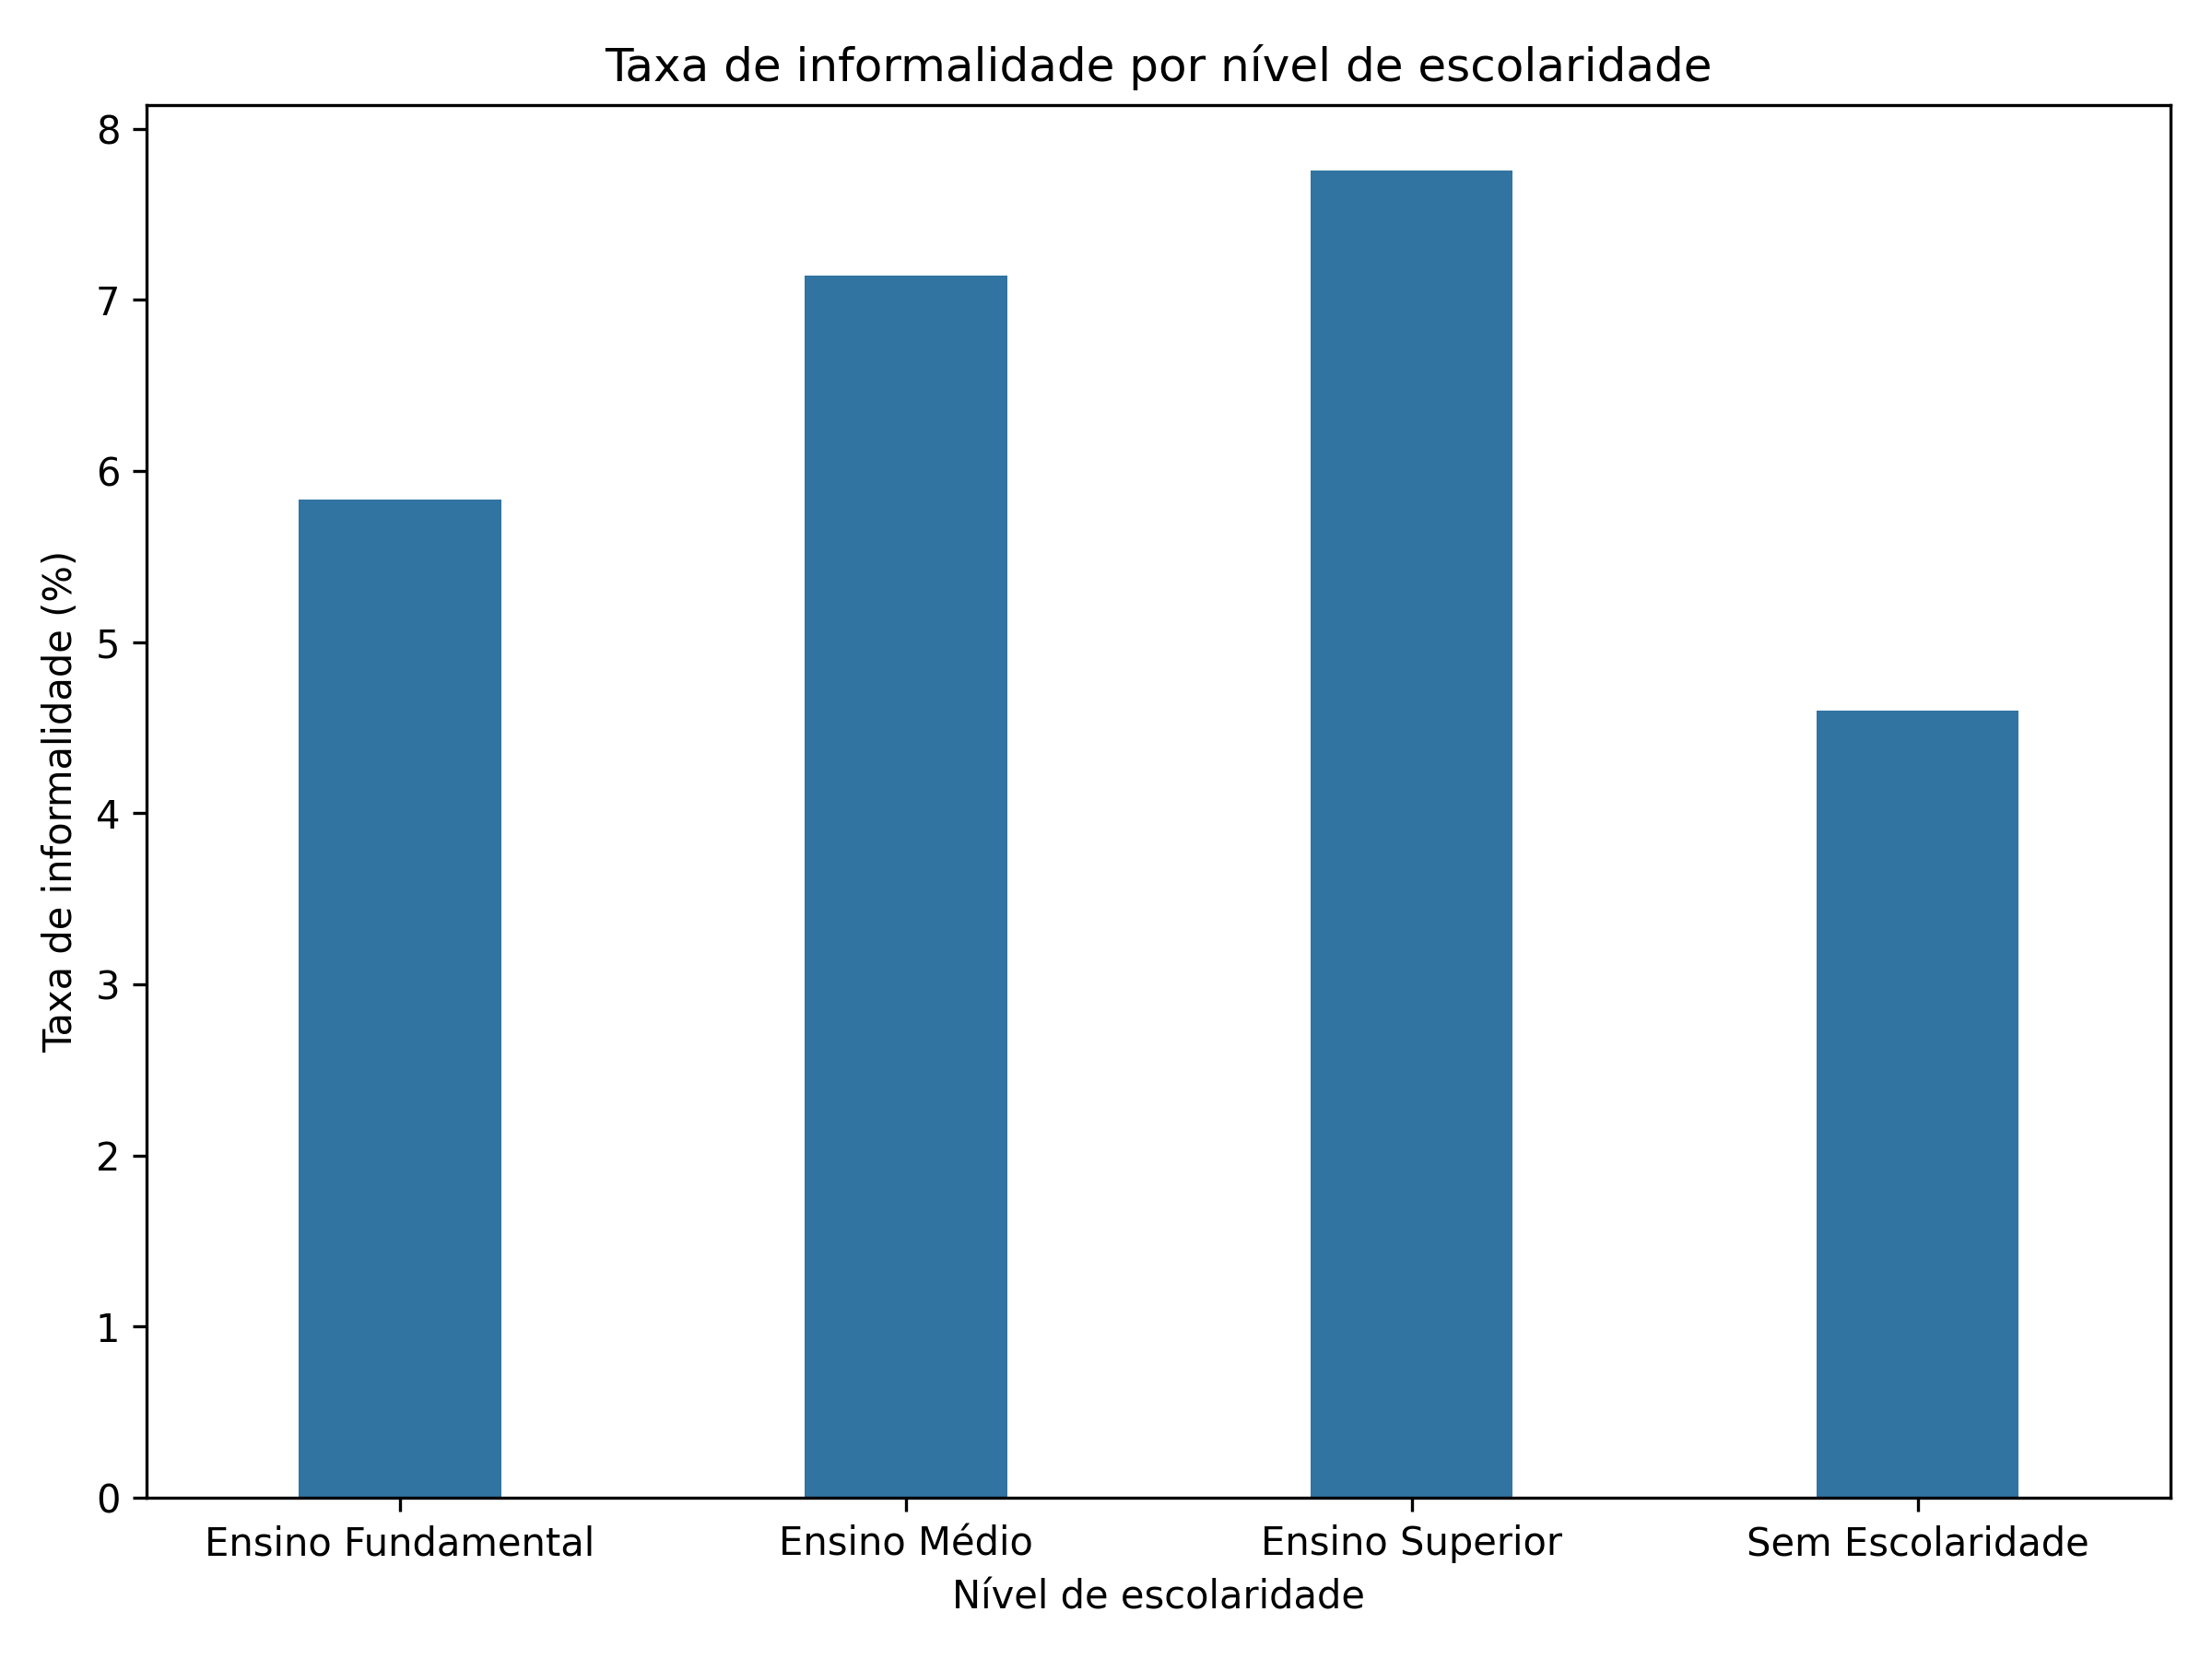

### Pergunta 3 - Perfil de vulnerabilidade e acessibilidade de pessoas com deficiência (PCD)

Não foi possível determinar a proporção de pessoas com deficiência (PCD) por faixa etária, e nem a porcentagem dessas pessoas que vivem na extrema pobreza, já que a amostra de dados trabalhada estava sem valores na coluna que indica deficiência.

### Pergunta 4 - Impacto da presença de crianças na ocupação das mães

Ao analisar o comportamento de mulheres responsáveis familiares com e sem crianças de 0 a 6 anos na família quanto à ocupação (trabalho remunerado, formal ou informal), constatou-se que as que possuem crianças nessa faixa etária na família tendem a ter uma taxa de ocupação um pouco maior do que as que não tem, sendo, em percentual, 41,18% contra 38,79%, o que representa uma variação de 2,39 pontos percentuais, aproximadamente. Esse resultado é, de certa forma, contra-intuitivo, já que a maternidade é frequentemente associada em nossa sociedade à uma redução na jornada de trabalho para assegurar os cuidados à criança nessa fase. No entanto, considerando que a base de dados é do CadÚnico (programa voltado para famílias de baixa renda), pode-se supor que a presença de uma criança nessa idade pode aumentar a necessidade financeira da família, o que leva a mãe a buscar fontes de renda complementares.

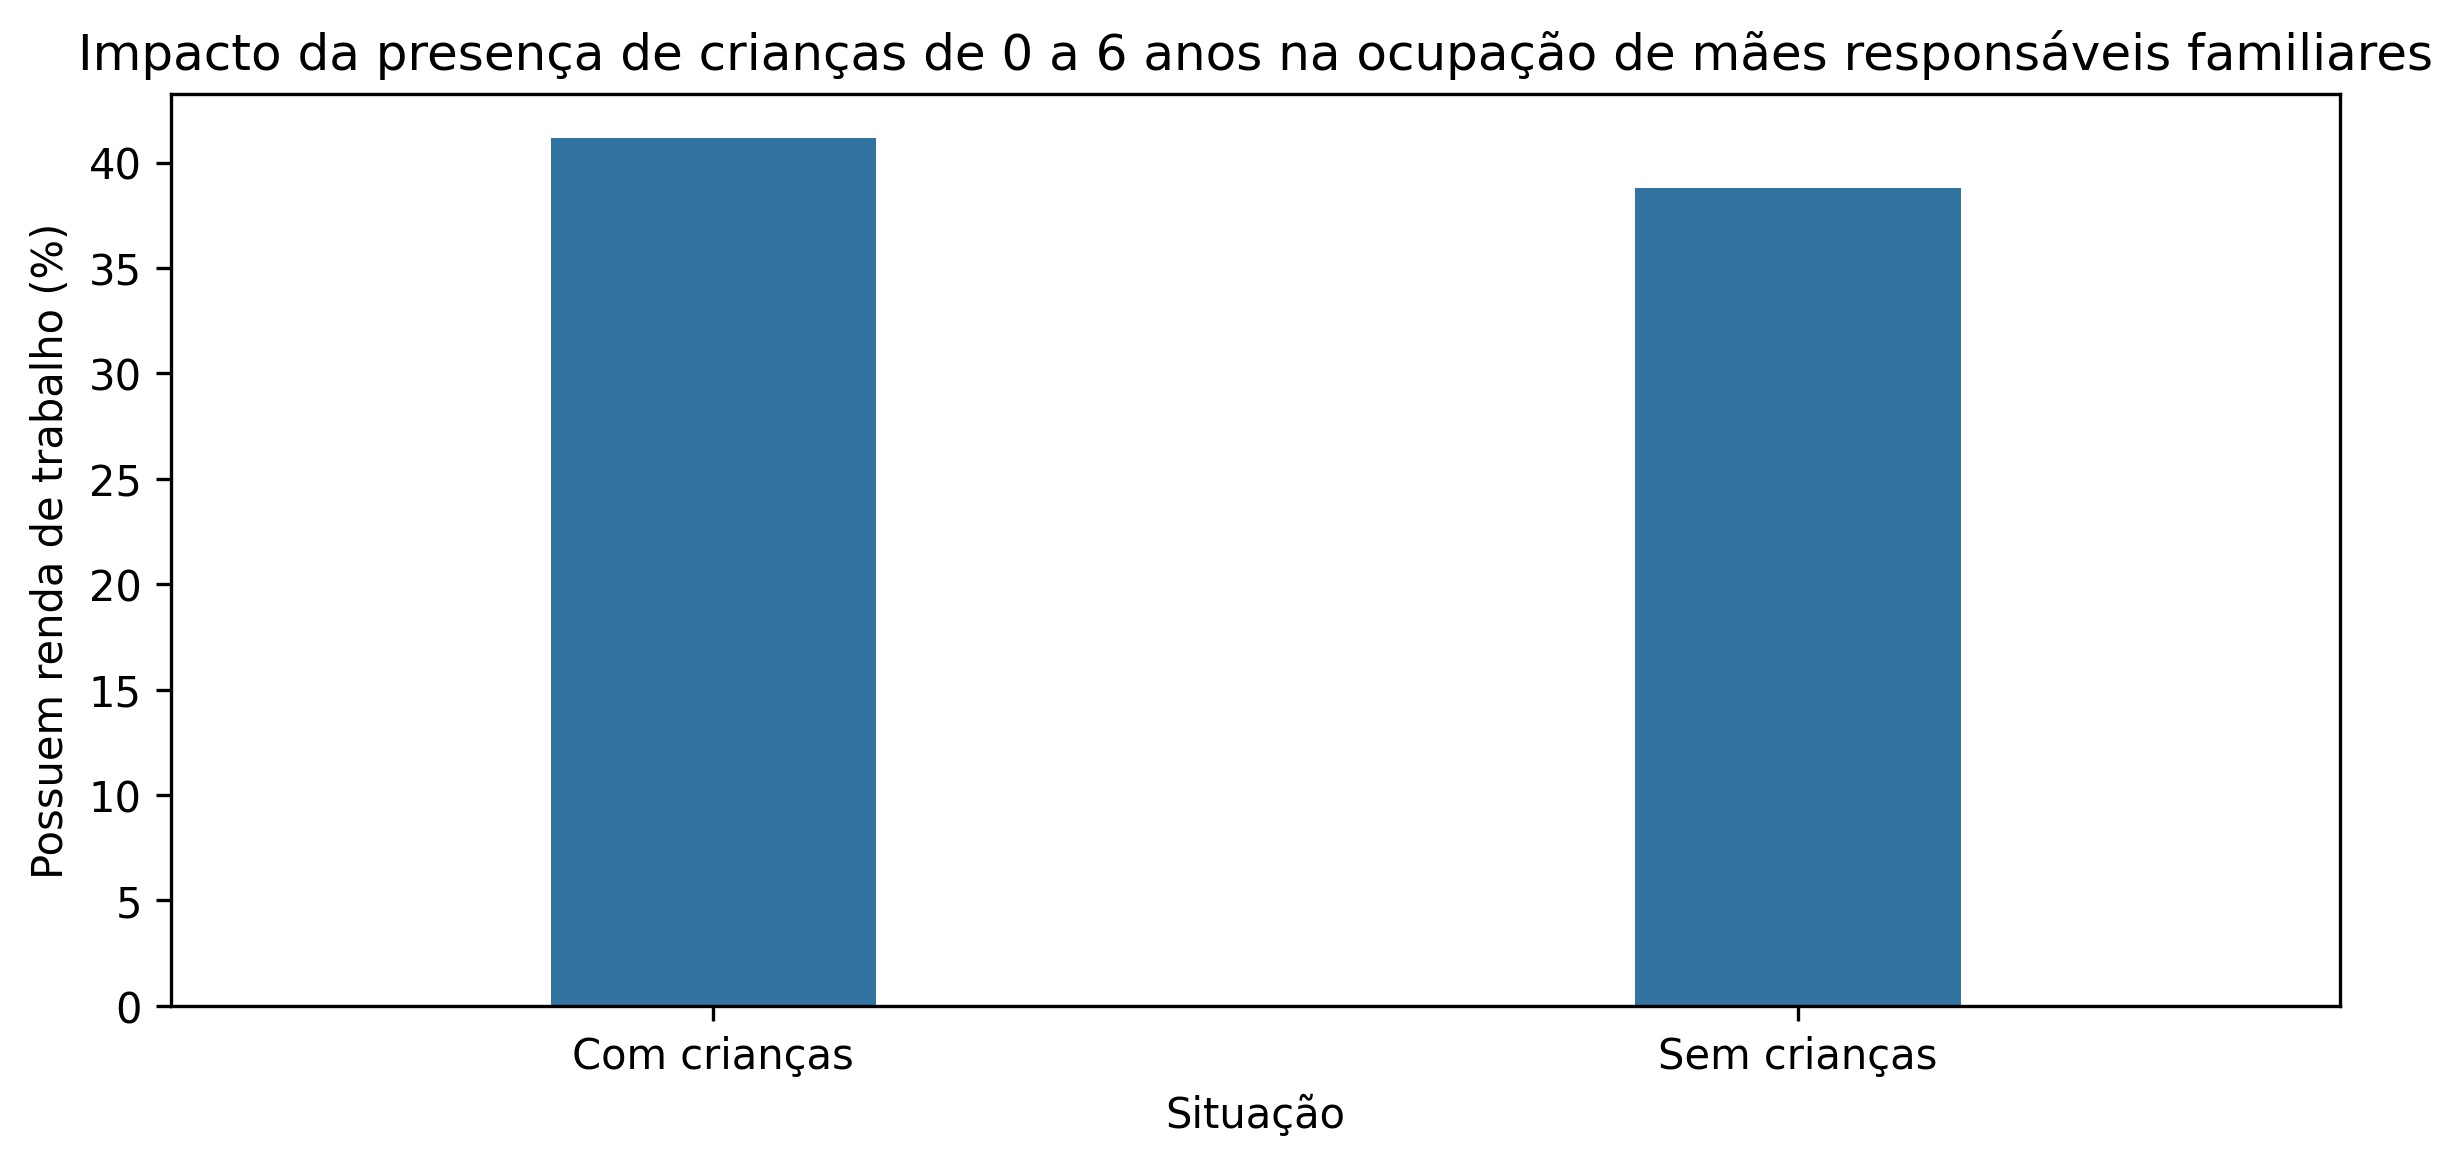

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
import os

In [4]:

os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 8g --executor-memory 8g pyspark-shell"

spark = SparkSession.builder \
    .appName("Colab_Optimized") \
    .master("local[*]") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "8g") \
    .config("spark.sql.shuffle.partitions", "4") \
    .config("spark.default.parallelism", "4") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .getOrCreate()

In [5]:
caminho_entrada = f'/content/drive/MyDrive/AmostraDS/amostra.csv'

In [6]:
schema_ddl  = "CD_IBGE_CADASTRO BIGINT, CO_FAMILIAR_FAM BIGINT, MARC_PBF INT, CO_CHV_NATURAL_PESSOA INT, IN_TRABALHO_INFANTIL_PESSOA BOOLEAN, CO_SEXO_PESSOA BYTE, DT_NASC_PESSOA DATE, CO_PARENTESCO_RF_PESSOA BYTE, CO_RACA_COR_PESSOA BYTE, CO_DEFICIENCIA_MEMB BOOLEAN, CO_SABE_LER_ESCREVER_MEMB BOOLEAN, IN_FREQUENTA_ESCOLA_MEMB BYTE, CO_CURSO_FREQUENTA_MEMB BYTE, CO_ANO_SERIE_FREQUENTA_MEMB BYTE, CO_CURSO_FREQ_PESSOA_MEMB BYTE, CO_ANO_SERIE_FREQUENTOU_MEMB BYTE, CO_CONCLUIU_FREQUENTOU_MEMB BOOLEAN, CO_TRABALHOU_SEMANA_MEMB BOOLEAN, CO_AGRICULTURA_TRAB_MEMB BOOLEAN, VL_REMUNER_EMPREGO_MEMB INT, VL_RENDA_BRUTA_12_MESES_MEMB INT, VL_RENDA_DOACAO_MEMB INT, VL_RENDA_APOSENT_MEMB INT, VL_RENDA_SEGURO_DESEMP_MEMB INT, VL_RENDA_PENSAO_ALIMEN_MEMB INT, VL_RENDA_OUTRAS_MEMB INT"

In [7]:
df_cad = spark.read.csv(caminho_entrada, header=True, schema=schema_ddl)

In [8]:
print(df_cad.columns)

['CD_IBGE_CADASTRO', 'CO_FAMILIAR_FAM', 'MARC_PBF', 'CO_CHV_NATURAL_PESSOA', 'IN_TRABALHO_INFANTIL_PESSOA', 'CO_SEXO_PESSOA', 'DT_NASC_PESSOA', 'CO_PARENTESCO_RF_PESSOA', 'CO_RACA_COR_PESSOA', 'CO_DEFICIENCIA_MEMB', 'CO_SABE_LER_ESCREVER_MEMB', 'IN_FREQUENTA_ESCOLA_MEMB', 'CO_CURSO_FREQUENTA_MEMB', 'CO_ANO_SERIE_FREQUENTA_MEMB', 'CO_CURSO_FREQ_PESSOA_MEMB', 'CO_ANO_SERIE_FREQUENTOU_MEMB', 'CO_CONCLUIU_FREQUENTOU_MEMB', 'CO_TRABALHOU_SEMANA_MEMB', 'CO_AGRICULTURA_TRAB_MEMB', 'VL_REMUNER_EMPREGO_MEMB', 'VL_RENDA_BRUTA_12_MESES_MEMB', 'VL_RENDA_DOACAO_MEMB', 'VL_RENDA_APOSENT_MEMB', 'VL_RENDA_SEGURO_DESEMP_MEMB', 'VL_RENDA_PENSAO_ALIMEN_MEMB', 'VL_RENDA_OUTRAS_MEMB']


In [9]:
df_cad.show()

+----------------+---------------+--------+---------------------+---------------------------+--------------+--------------+-----------------------+------------------+-------------------+-------------------------+------------------------+-----------------------+---------------------------+-------------------------+----------------------------+---------------------------+------------------------+------------------------+-----------------------+----------------------------+--------------------+---------------------+---------------------------+---------------------------+--------------------+
|CD_IBGE_CADASTRO|CO_FAMILIAR_FAM|MARC_PBF|CO_CHV_NATURAL_PESSOA|IN_TRABALHO_INFANTIL_PESSOA|CO_SEXO_PESSOA|DT_NASC_PESSOA|CO_PARENTESCO_RF_PESSOA|CO_RACA_COR_PESSOA|CO_DEFICIENCIA_MEMB|CO_SABE_LER_ESCREVER_MEMB|IN_FREQUENTA_ESCOLA_MEMB|CO_CURSO_FREQUENTA_MEMB|CO_ANO_SERIE_FREQUENTA_MEMB|CO_CURSO_FREQ_PESSOA_MEMB|CO_ANO_SERIE_FREQUENTOU_MEMB|CO_CONCLUIU_FREQUENTOU_MEMB|CO_TRABALHOU_SEMANA_MEMB|CO_AGRI

In [10]:
print ("a amostra possui ", df_cad.select("CD_IBGE_CADASTRO").distinct().count(), " municipios distintos")

a amostra possui  5570  municipios distintos


In [11]:
print( "sendo ", df_cad.filter(df_cad["CD_IBGE_CADASTRO"] == 3162500).count(), " de São joão del Rei")

sendo  9454  de São joão del Rei


In [12]:
df_cad.groupBy("CO_SEXO_PESSOA").count().show()

+--------------+-------+
|CO_SEXO_PESSOA|  count|
+--------------+-------+
|             2|4153746|
|             1|3218110|
+--------------+-------+



In [13]:
total_mulheres_rf = df_cad.filter(
    (df_cad["CO_SEXO_PESSOA"] == 2) &
    (df_cad["CO_PARENTESCO_RF_PESSOA"] == 1) &
    (df_cad["VL_REMUNER_EMPREGO_MEMB"] > 0)
).count()

In [14]:
total_mulheres_rf

811982

In [15]:
total_homens_rf = df_cad.filter(
    (df_cad["CO_SEXO_PESSOA"] == 1) &
    (df_cad["CO_PARENTESCO_RF_PESSOA"] == 1) &
    (df_cad["VL_REMUNER_EMPREGO_MEMB"] > 0)
).count()

In [16]:
total_homens_rf

180695

In [17]:
from pyspark.sql.functions import avg
df_cad.groupBy("CD_IBGE_CADASTRO", "CO_SEXO_PESSOA").agg(
    avg("VL_REMUNER_EMPREGO_MEMB").alias("media_renda")
).show()

+----------------+--------------+------------------+
|CD_IBGE_CADASTRO|CO_SEXO_PESSOA|       media_renda|
+----------------+--------------+------------------+
|         2107357|             1| 67.43793911007026|
|         2411601|             2|              94.6|
|         3550308|             2|335.48858440850444|
|         2505303|             1|59.127272727272725|
|         1702406|             1|128.69098712446353|
|         4314308|             1| 542.8478260869565|
|         2112407|             1|47.929597701149426|
|         4307708|             2|115.38682432432432|
|         3106200|             2|223.02146116149382|
|         2932457|             2| 66.92561983471074|
|         4101804|             1| 338.1098376313276|
|         2807204|             1| 92.25333333333333|
|         2614501|             1|48.579268292682926|
|         2917300|             1|106.87674418604651|
|         3300308|             1|213.52110625909754|
|         1505106|             1|144.516666666

In [18]:
from pyspark.sql.window import Window
from pyspark.sql.functions import avg


janela_sexo = Window.partitionBy("CO_SEXO_PESSOA")


df_cad_com_media = df_cad.withColumn(
    "MEDIA_RENDA_SEXO",
    avg("VL_REMUNER_EMPREGO_MEMB").over(janela_sexo)
)


df_cad_com_media.select("CO_SEXO_PESSOA", "VL_REMUNER_EMPREGO_MEMB", "MEDIA_RENDA_SEXO").show(10)

+--------------+-----------------------+-----------------+
|CO_SEXO_PESSOA|VL_REMUNER_EMPREGO_MEMB| MEDIA_RENDA_SEXO|
+--------------+-----------------------+-----------------+
|             2|                    954|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                   NULL|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                    780|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                      0|148.2465598188438|
|             2|                   NULL|148.2465598188438|
|             2|                      0|148.2465598188438|
+--------------+-----------------------+-----------------+
only showing top 10 rows


In [19]:
df_cad_com_media = df_cad_com_media.withColumn(
    "DIFERENCA_RENDA_MEDIA",
    col("VL_REMUNER_EMPREGO_MEMB") - col("MEDIA_RENDA_SEXO")
)

df_cad_com_media.select(
    "CO_SEXO_PESSOA",
    "VL_REMUNER_EMPREGO_MEMB",
    "MEDIA_RENDA_SEXO",
    "DIFERENCA_RENDA_MEDIA"
).show(10)

+--------------+-----------------------+-----------------+---------------------+
|CO_SEXO_PESSOA|VL_REMUNER_EMPREGO_MEMB| MEDIA_RENDA_SEXO|DIFERENCA_RENDA_MEDIA|
+--------------+-----------------------+-----------------+---------------------+
|             2|                    954|148.2465598188438|    805.7534401811562|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                   NULL|148.2465598188438|                 NULL|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                    780|148.2465598188438|    631.7534401811562|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                      0|148.2465598188438|   -148.2465598188438|
|             2|                   NULL|148.2465598188438|                 NULL|
|             2|            

In [20]:
import pandas as pd

#Trouxemos para pandas somente as colunas do dataset que nos foram úteis (18 no total)
df_pandas = df_cad.select(
"DT_NASC_PESSOA",
"CO_SEXO_PESSOA",
"CO_RACA_COR_PESSOA",
"VL_RENDA_BRUTA_12_MESES_MEMB",
"VL_REMUNER_EMPREGO_MEMB",
"CO_CURSO_FREQ_PESSOA_MEMB",
"CO_ANO_SERIE_FREQUENTA_MEMB",
"CO_DEFICIENCIA_MEMB",
"CO_FAMILIAR_FAM",
"VL_RENDA_DOACAO_MEMB",
"VL_RENDA_APOSENT_MEMB",
"VL_RENDA_SEGURO_DESEMP_MEMB",
"VL_RENDA_PENSAO_ALIMEN_MEMB",
"VL_RENDA_OUTRAS_MEMB",
"CD_IBGE_CADASTRO",
"CO_CURSO_FREQUENTA_MEMB",
"CO_PARENTESCO_RF_PESSOA",
"CO_CHV_NATURAL_PESSOA",
).toPandas()

import matplotlib.pyplot as mp
import seaborn as sb

import numpy as np

# Etapa 1: Análise demográfica e mercado de trabalho

## Questão 1

In [21]:
df_pandas["DT_NASC_PESSOA"] = pd.to_datetime(df_pandas["DT_NASC_PESSOA"], errors="coerce")
dataAtual = pd.Timestamp("2018-06-01") #Considerou-se que os dados eram de 2018 e o mês foi escolhido arbitrariamente, na falta da data precisa do levantamento.

#Cálculo das idades com base na data estimada do levantamento e na data de nascimento de cada pessoa
df_pandas["IDADE"] = (dataAtual.year - df_pandas["DT_NASC_PESSOA"].dt.year -
((df_pandas["DT_NASC_PESSOA"].dt.month > dataAtual.month) |
 ((df_pandas["DT_NASC_PESSOA"].dt.month == dataAtual.month) & (df_pandas["DT_NASC_PESSOA"].dt.day > dataAtual.day))) )

df_pandas.loc[df_pandas["IDADE"] > 110, "IDADE"] = None #Remoção de todas as idades maiores que 110, pois foram consideradas erros do levantamento

In [22]:
#Agrupamos por sexo e raça/cor, e aplicamos dentro de cada grupo a média, mediana e média, com o auxílio da função 'agg'
resultadoIdade = df_pandas.groupby(["CO_SEXO_PESSOA", "CO_RACA_COR_PESSOA"])["IDADE"].agg(["mean", "median", "std"])
resultadoIdade.columns = ["Media", "Mediana", "Desvio_Padrao"]
print(resultadoIdade)

                                       Media  Mediana  Desvio_Padrao
CO_SEXO_PESSOA CO_RACA_COR_PESSOA                                   
1              1.0                 27.022408     20.0      22.102589
               2.0                 31.140044     28.0      20.985049
               3.0                 26.739897     20.0      22.049055
               4.0                 24.995207     19.0      20.025204
               5.0                 20.492254     15.0      17.125525
2              1.0                 30.705862     28.0      21.430975
               2.0                 34.181035     33.0      19.106221
               3.0                 30.369697     28.0      20.383229
               4.0                 28.024229     25.0      19.255332
               5.0                 22.653668     19.0      16.851665


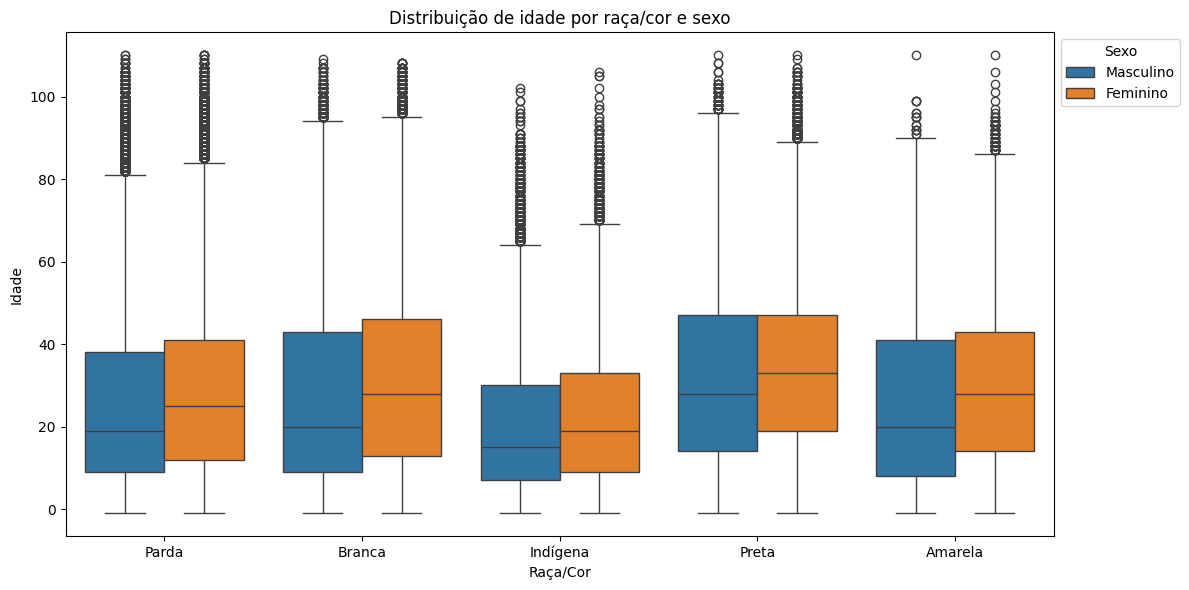

In [23]:
#PLOTAGEM DO GRÁFICO DA QUESTÃO 1 - Sessão 1

#Lógica de transformação dos códigos numéricos em seus respectivos significados, usando de 'map' + dicionário

#Quanto ao sexo:
mapa_sexo = {
    1 : "Masculino",
    2 : "Feminino"
}
df_pandas["SEXO_SIGNIFICADO"] = df_pandas["CO_SEXO_PESSOA"].map(mapa_sexo)

#Quanto à raça/cor:
mapa_raca_cor = {
    1 : "Branca",
    2 : "Preta",
    3 : "Amarela",
    4 : "Parda",
    5 : "Indígena",
}
df_pandas["COR_RACA_SIGNIFICADO"] = df_pandas["CO_RACA_COR_PESSOA"].map(mapa_raca_cor)

#Plotagem do gráfico boxplot para os dados encontrados
mp.figure(figsize = (12, 6)) #tamanho da janela
grafico = sb.boxplot(data=df_pandas, x="COR_RACA_SIGNIFICADO", y="IDADE", hue="SEXO_SIGNIFICADO") #definição de dados do gráfico
grafico.legend(title="Sexo", loc = "upper left", bbox_to_anchor = (1,1)) #definição de título e posição da legenda dentro da janela
mp.xlabel("Raça/Cor") #rótulo do eixo X
mp.ylabel("Idade") #rótulo do eixo Y
mp.title("Distribuição de idade por raça/cor e sexo") #título do gráfico
mp.tight_layout() #layout
mp.show() #"desenha" o gráfico

## Questão 2

In [24]:

#Lógica de classificação do trabalho em formal(2) ou informal(1), com o auxílio do método 'select' da biblioteca numpy:

#define condições. Caso se satisfaça a condição na posição i, então é atribuído o valor da posição i de 'valores' para esse indivíduo
condicoes = [
    ((df_pandas["VL_RENDA_BRUTA_12_MESES_MEMB"] != 0) & (df_pandas["VL_REMUNER_EMPREGO_MEMB"] == 0)),
    (df_pandas["VL_REMUNER_EMPREGO_MEMB"] != 0),
]

valores = [
    1,
    2,
]

df_pandas["FORMALIDADE_TRABALHO"] = np.select(condicoes, valores, default=0)

#filtra os indíviduos com idade entre 18 e 65 anos e que possuem trabalho (formal ou informal)
adultos_trabalhando = df_pandas[((df_pandas["IDADE"]>= 18) & (df_pandas["IDADE"]<=65) & (df_pandas["FORMALIDADE_TRABALHO"].isin([1, 2])))]

#Cada uma das seguintes linhas faz uma comparação sobre os valores da coluna especificada, retornando uma Series de bool (true caso a comparação se satisfaça).
#Assim, ao aplicar o .sum(), o python converte 'true' para 1 e 'false' para 0, permitindo obter a quantidade de elementos que satisfazem a condição.
qtd_informais = (adultos_trabalhando["FORMALIDADE_TRABALHO"] == 1).sum()
qtd_formais = (adultos_trabalhando["FORMALIDADE_TRABALHO"] == 2).sum()

total_trabalhadores = qtd_informais + qtd_formais

taxa_informais = (qtd_informais / total_trabalhadores)*100
taxa_formais = (qtd_formais / total_trabalhadores)*100

print (pd.DataFrame({
    "Tipo de Trabalhador" : ["Informal", "Formal"],
    "Quantidade": [qtd_informais, qtd_formais],
    "Taxa (%)": [taxa_informais, taxa_formais]
}))


  Tipo de Trabalhador  Quantidade   Taxa (%)
0            Informal     2438697  60.179109
1              Formal     1613701  39.820891


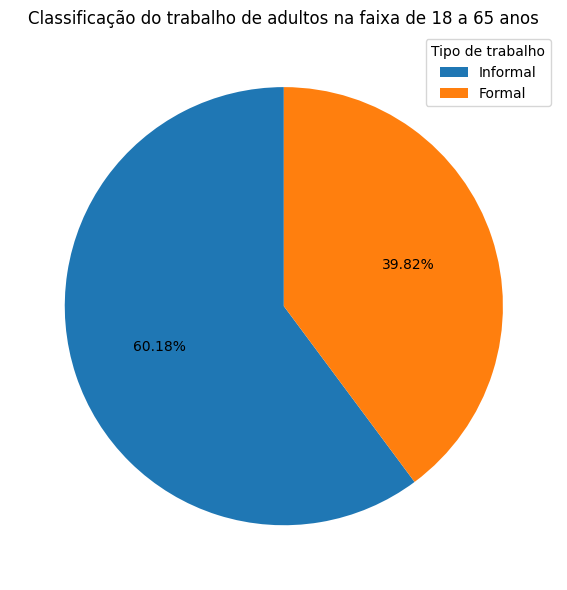

In [52]:
#PLOTAGEM DO GRÁFICO DA QUESTÃO 2 - Sessão 1

mapa_class_trabalho = {
    1 : "Informal",
    2 : "Formal"
}

#Converte os códigos numéricos no significado e conta quantos tem de cada um, retornando uma Series com as quantidades
contagem = adultos_trabalhando["FORMALIDADE_TRABALHO"].map(mapa_class_trabalho).value_counts()

#Plotagem do gráfico de pizza representando os dados encontrados
mp.figure(figsize = (6, 6))
mp.pie (
    contagem.values, #contagem de cada categoria, necessário para o cálculo automático da porcentagem
    labels = None, #tira a legenda automática (critérios estéticos apenas)
    autopct="%1.2f%%", #define que a porcentagem deve aparecer com duas casas decimais dentro de cada fatia
    startangle=90 #define que as fatias do gráfico comecem às 12h (apenas estética)
)
mp.title("Classificação do trabalho de adultos na faixa de 18 a 65 anos")
mp.legend(contagem.index, title="Tipo de trabalho") #montagem da janelinha de legendas
mp.tight_layout()
mp.show()

## Questão 3

In [54]:

#Lógica de atribuição de significado aos valores numéricos definidos no dicionário do cadUnico

#OBS: nessa etapa foi feita uma divisão generalista do nível escolar, não diferenciando turmas EJA e especiais das demais, por exemplo.

#considerando indivíduos que já não estudam mais
condicoes = [
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"].isin([1, 2, 3]),
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"].isin([4, 5, 6, 7, 10, 11]),
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"].isin([8, 9, 12]),
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"] == 13,
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"] == 14,
    df_pandas["CO_CURSO_FREQ_PESSOA_MEMB"] == 15,
]

valores = [
    "Educação Infantil",
    "Ensino Fundamental",
    "Ensino Médio",
    "Ensino Superior",
    "Alfabetização de Adultos",
    "Sem Escolaridade",
]

#preenchimento provisório de NIVEL_ESCOLARIDADE, pois ainda não contém os dados de estudantes que ainda estudam
df_pandas["NIVEL_ESCOLARIDADE"] = np.select(
    condicoes,
    valores,
    default = "Não informado"
)

#considerando indíviduos que ainda estudam
condicoes_frequenta = [
    df_pandas["CO_CURSO_FREQUENTA_MEMB"].isin([1, 2, 3]),
    df_pandas["CO_CURSO_FREQUENTA_MEMB"].isin([4, 5, 6, 9, 10]),
    df_pandas["CO_CURSO_FREQUENTA_MEMB"].isin([7, 8, 11]),
    df_pandas["CO_CURSO_FREQUENTA_MEMB"] == 13,
    df_pandas["CO_CURSO_FREQUENTA_MEMB"] == 12,
    df_pandas["CO_CURSO_FREQUENTA_MEMB"] == 14,
]

nivel_esc_atual = np.select(
    condicoes_frequenta,
    valores,
    default=None,
)

#'estuda_agora' é um DataFrame que armazena somente indivíduos em que "CO_CURSO_FREQUENTA_MEMB" tem algum valor
estuda_agora = df_pandas["CO_CURSO_FREQUENTA_MEMB"].notna()

#localizamos os indivíduos que ainda estudam, selecionamos "NIVEL_ESCOLARIDADE", que até então estava sem valor e atribuímos o nível escolar real, que foi
#definido conforme visto acima. Agora, temos a coluna de nível de escolaridade completa
df_pandas.loc[estuda_agora, "NIVEL_ESCOLARIDADE"] = nivel_esc_atual[estuda_agora]

resultado = df_pandas.groupby("NIVEL_ESCOLARIDADE").agg(
    Renda_Media = ("VL_REMUNER_EMPREGO_MEMB", "mean") #cria uma coluna para 'resultado' que é a média de VL_REMUNER_EMPREGO_MEMB dentro de cada nível de escolaridade
)

print (resultado)


                          Renda_Media
NIVEL_ESCOLARIDADE                   
Alfabetização de Adultos    76.005329
Educação Infantil           64.630704
Ensino Fundamental         147.116145
Ensino Médio               223.439581
Ensino Superior            571.264252
Não informado               61.635183
Sem Escolaridade           122.414775


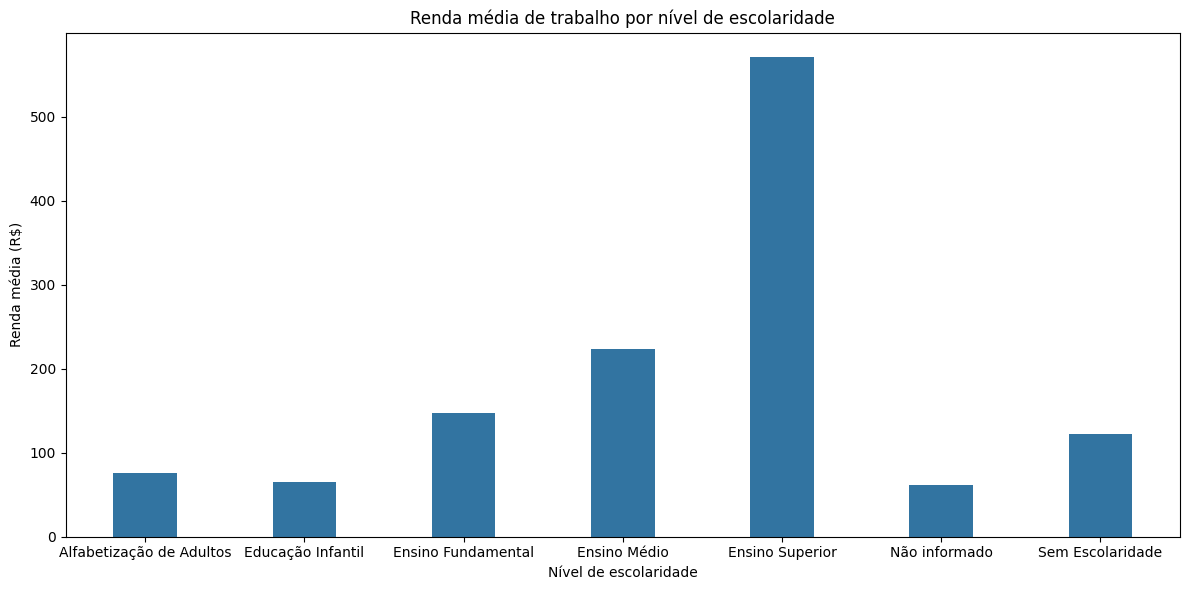

In [56]:
#PLOTAGEM DO GRÁFICO DA QUESTÃO 3 - Sessão 1

mp.figure(figsize = (12, 6))
sb.barplot(x=resultado.index, y=resultado["Renda_Media"], width=0.4) #define-se aqui as medidas de cada eixo
mp.title("Renda média de trabalho por nível de escolaridade")
mp.xlabel("Nível de escolaridade")
mp.ylabel("Renda média (R$)")

mp.tight_layout()
mp.show()


# Etapa 2: Análise do perfil de trabalho e escolaridade

## Questão 1

In [28]:
#Lógica de atribuição de significado aos valores númericos de "IDADE". Esse trecho divide os indivíduos dentre 5 faixas etárias, ou "Não declarado", caso o campo de
#data de nascimento esteja sem valor
condicoes = [
    df_pandas["IDADE"].between(0, 12),
    df_pandas["IDADE"].between(13, 17),
    df_pandas["IDADE"].between(18, 29),
    df_pandas["IDADE"].between(30, 59),
    df_pandas["IDADE"]>=60
]

valores = [
    "Criança",
    "Adolescente",
    "Jovem",
    "Adulto",
    "Idoso"
]

df_pandas["FAIXA_ETARIA"] = np.select(
    condicoes,
    valores,
    default = "Não declarado"
)

In [29]:
resultado = df_pandas.groupby("FAIXA_ETARIA").agg(
    TOTAL = ("FAIXA_ETARIA", "size"), #total de pessoas por faixa etária
    POSSUI_TRABALHO  = ("VL_REMUNER_EMPREGO_MEMB", lambda x : (x > 0).sum()) #total de pessoas por faixa etária que possuem trabalho
)

resultado["PROPORCAO_(%)"] = (resultado["POSSUI_TRABALHO"] / resultado["TOTAL"]) * 100

print (resultado)


                 TOTAL  POSSUI_TRABALHO  PROPORCAO_(%)
FAIXA_ETARIA                                          
Adolescente     818185             8763       1.071029
Adulto         2387351          1144435      47.937442
Criança        2063898                7       0.000339
Idoso           667137            66335       9.943235
Jovem          1402361           412079      29.384659
Não declarado    32924               65       0.197424


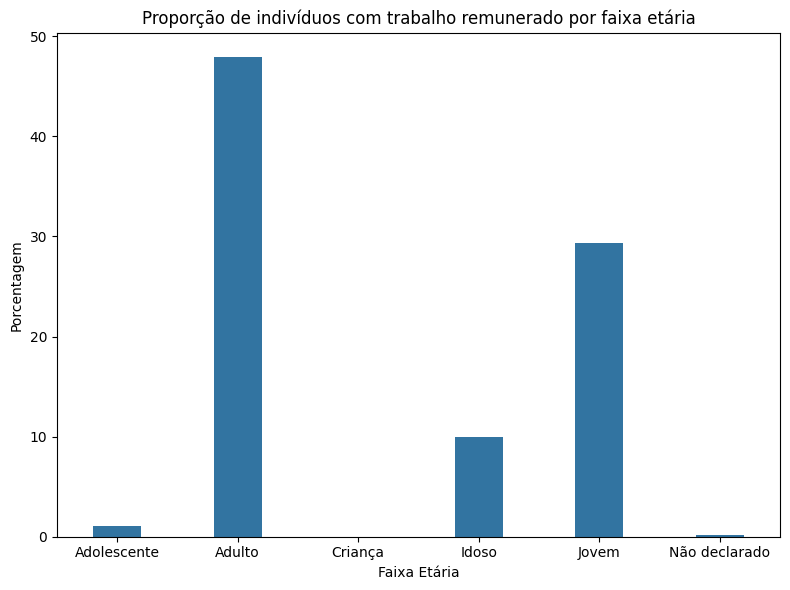

In [30]:
#PLOTAGEM DO GRÁFICO DA QUESTÃO 1 - Sessão 2

mp.figure(figsize = (8, 6))
sb.barplot(x=resultado.index, y=resultado["PROPORCAO_(%)"], width=0.4)
mp.title("Proporção de indivíduos com trabalho remunerado por faixa etária")
mp.xlabel("Faixa Etária")
mp.ylabel("Porcentagem")

mp.tight_layout()
mp.show()

## Questão 2

In [31]:
rendas = [
    "VL_REMUNER_EMPREGO_MEMB",
    "VL_RENDA_APOSENT_MEMB",
    "VL_RENDA_SEGURO_DESEMP_MEMB",
    "VL_RENDA_PENSAO_ALIMEN_MEMB",
    "VL_RENDA_OUTRAS_MEMB",
]

#A fim de se obter a totalidade das fontes de renda de cada indivíduo, valores problemáticos foram substituídos por 0 e, em seguida, foi feita uma soma de cada
#fonte de renda por indíviduo, armazenando a totalidade numa nova coluna de df_pandas
df_pandas["RENDA_TOTAL"] = df_pandas[rendas].fillna(0).sum(axis=1)

#agrupou-se indivíduos com código familiar igual (de mesma família), a fim de obter-se alguns dados relevantes:
familias = (df_pandas.groupby("CO_FAMILIAR_FAM").agg(
    RENDA_FAMILIAR = ("RENDA_TOTAL", "sum"), #pela soma da renda total de cada indivíduo, obteve-se a renda familiar de cada indivíduo
    NUM_MEMBROS_FAMILIA = ("RENDA_TOTAL", "size"), #obteve-se ainda o número de membros na família de cada um (necessário para o cálculo da renda per capita, posteriormente)
)).reset_index()

familias["RENDA_PER_CAPITA"] = familias["RENDA_FAMILIAR"] / familias["NUM_MEMBROS_FAMILIA"]

salario_min = 954 #foi considerado o salário mínimo no ano de 2018

condicoes = [
    familias["RENDA_PER_CAPITA"] <= 109,
    familias["RENDA_PER_CAPITA"] <= 218,
    familias["RENDA_PER_CAPITA"] <= (salario_min/2),
    familias["RENDA_PER_CAPITA"] > (salario_min/2),
]

valores = [
    1,
    2,
    3,
    4,
]

familias["CLASS_FAIXA_RENDA_FAM"] = np.select(
    condicoes,
    valores,
    default = 0,
)

#para obter algumas das respostas, precisávamos correlacionar colunas de 'df_pandas' com colunas de 'familias', mas, no entanto, esses DataFrame possuem número diferente
#de registros. Como solução, usou-se o 'merge', que é capaz de "distribuir" os dados de 'familias' em df_pandas novamente, com base no código familiar. Dessa forma,
#todos os indivíduos com código familiar igual, recebem os mesmos valores.
df_pandas = df_pandas.merge(familias[["CO_FAMILIAR_FAM", "RENDA_PER_CAPITA", "CLASS_FAIXA_RENDA_FAM"]], on="CO_FAMILIAR_FAM")

numDeficientes = df_pandas[df_pandas["CO_DEFICIENCIA_MEMB"] == 1].groupby("CLASS_FAIXA_RENDA_FAM").size()
numTotalPorFaixa = familias.groupby("CLASS_FAIXA_RENDA_FAM")["NUM_MEMBROS_FAMILIA"].sum()

percentual = (numDeficientes / numTotalPorFaixa) * 100

resultado = pd.DataFrame({
    "NUM_DEFICIENTES" : numDeficientes,
    "PORCENTAGEM" : percentual,
}).reset_index() #reset_index() para que class_faixa_renda_fam, que era o índice de numDeficientes e percentual volte a ser uma coluna de resultado

#OBS: aparentemente, a coluna "CO_DEFICIENCIA_MEMB" está sem valores. Devido a isso, não foi possível determinar a
#porcentagem de pessoas com deficiência por classe social.
print (resultado)


   CLASS_FAIXA_RENDA_FAM  NUM_DEFICIENTES  PORCENTAGEM
0                      1              NaN          NaN
1                      2              NaN          NaN
2                      3              NaN          NaN
3                      4              NaN          NaN


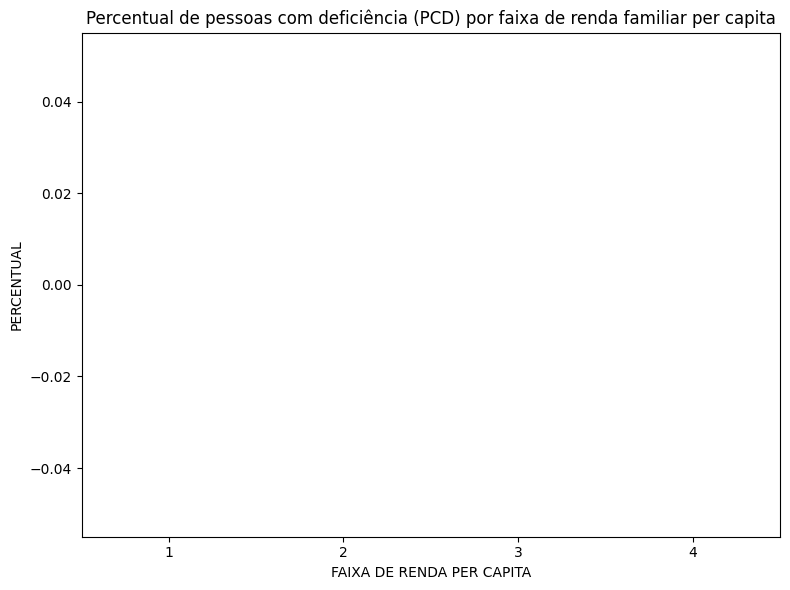

In [32]:
#PLOTAGEM DO GRÁFICO DA QUESTÃO 2 - Sessão 2

#Sem valores, pois a coluna "CO_DEFICIENCIA_MEMB" do dataset está sem dados.

mp.figure(figsize = (8, 6))
sb.barplot(x=resultado["CLASS_FAIXA_RENDA_FAM"], y=resultado["PORCENTAGEM"])
mp.title("Percentual de pessoas com deficiência (PCD) por faixa de renda familiar per capita")
mp.xlabel("FAIXA DE RENDA PER CAPITA")
mp.ylabel("PERCENTUAL")

mp.tight_layout()
mp.show()

# Perguntas

## Pergunta 1

In [33]:
trabalhadores = df_pandas[df_pandas["VL_REMUNER_EMPREGO_MEMB"] > 0]
resultado = trabalhadores.groupby(["SEXO_SIGNIFICADO", "COR_RACA_SIGNIFICADO"])["VL_REMUNER_EMPREGO_MEMB"].agg(["mean", "median"]).reset_index()
resultado.columns = ["Sexo", "Raca/Cor", "Média", "Mediana"]
print (resultado)

        Sexo  Raca/Cor       Média  Mediana
0   Feminino   Amarela  533.129800    320.0
1   Feminino    Branca  630.055964    450.0
2   Feminino  Indígena  347.985195    200.0
3   Feminino     Parda  447.600199    280.0
4   Feminino     Preta  478.533494    300.0
5  Masculino   Amarela  646.903576    400.0
6  Masculino    Branca  798.270632    700.0
7  Masculino  Indígena  421.414883    250.0
8  Masculino     Parda  527.829426    300.0
9  Masculino     Preta  602.077621    400.0


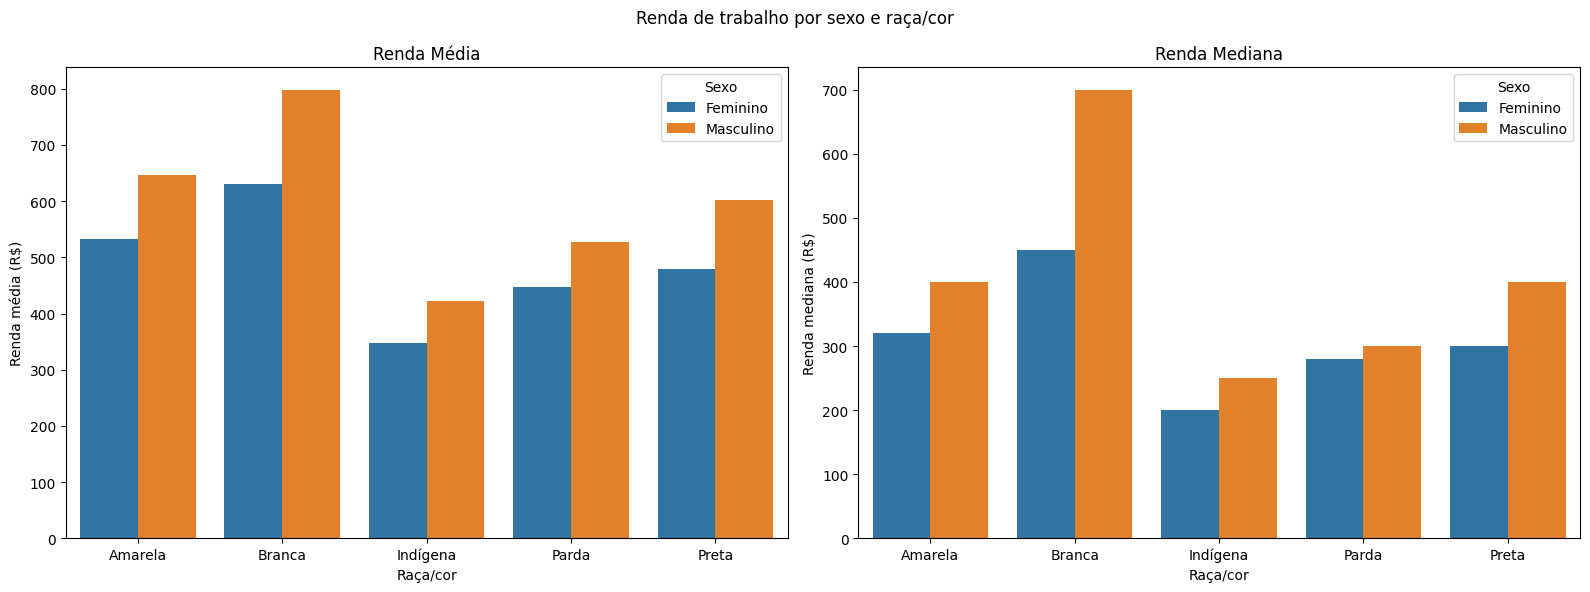

In [34]:
import os
os.makedirs("/content/drive/MyDrive/AmostraDS/graficos_relatorio", exist_ok=True)

fig, graficos = mp.subplots(1, 2, figsize=(16, 6))

sb.barplot(x=resultado["Raca/Cor"], y=resultado["Média"], hue=resultado["Sexo"], ax=graficos[0])
graficos[0].set_title("Renda Média")
graficos[0].set_xlabel("Raça/cor")
graficos[0].set_ylabel("Renda média (R$)")

sb.barplot(x=resultado["Raca/Cor"], y=resultado["Mediana"], hue=resultado["Sexo"], ax=graficos[1])
graficos[1].set_title("Renda Mediana")
graficos[1].set_xlabel("Raça/cor")
graficos[1].set_ylabel("Renda mediana (R$)")

mp.suptitle("Renda de trabalho por sexo e raça/cor")
mp.tight_layout()
mp.savefig("/content/drive/MyDrive/AmostraDS/graficos_relatorio/p1_renda_sexo_raca.png", dpi=300)
mp.show()

## Pergunta 2

In [35]:
#Tratando dados de renda/remuneração sem valor
renda_12_meses = df_pandas["VL_RENDA_BRUTA_12_MESES_MEMB"].fillna(0)
remuneracao_emprego = df_pandas["VL_REMUNER_EMPREGO_MEMB"].fillna(0)

#Classificação do trabalho de cada indivíduo em informal(1) ou formal(2)
condicoes = [
    (renda_12_meses != 0) & (remuneracao_emprego == 0),
    (remuneracao_emprego != 0),
]

valores = [
    1,
    2,
]

df_pandas["CLASS_TRABALHO"] = np.select(
    condicoes,
    valores,
    default=0,
)

#filtramos df_pandas por trabalhadores (formais(2) ou informais(1)), agrupamos os trabalhadores por nivel de escolaridade e aplicamos a seguinte função lambda sobre
#a coluna "CLASS_TRABALHO", que soma os informais e divide pelo total de trabalhadores, gerando o percentual de trabalhadores informais
percentual_informais = df_pandas[df_pandas["CLASS_TRABALHO"].isin([1, 2])].groupby("NIVEL_ESCOLARIDADE")["CLASS_TRABALHO"].apply(lambda x : (x == 1).sum() / (x.size) * 100)

print (percentual_informais)

NIVEL_ESCOLARIDADE
Alfabetização de Adultos    6.171491
Educação Infantil           4.239469
Ensino Fundamental          5.834679
Ensino Médio                7.139977
Ensino Superior             7.752777
Não informado               4.197883
Sem Escolaridade            4.600484
Name: CLASS_TRABALHO, dtype: float64


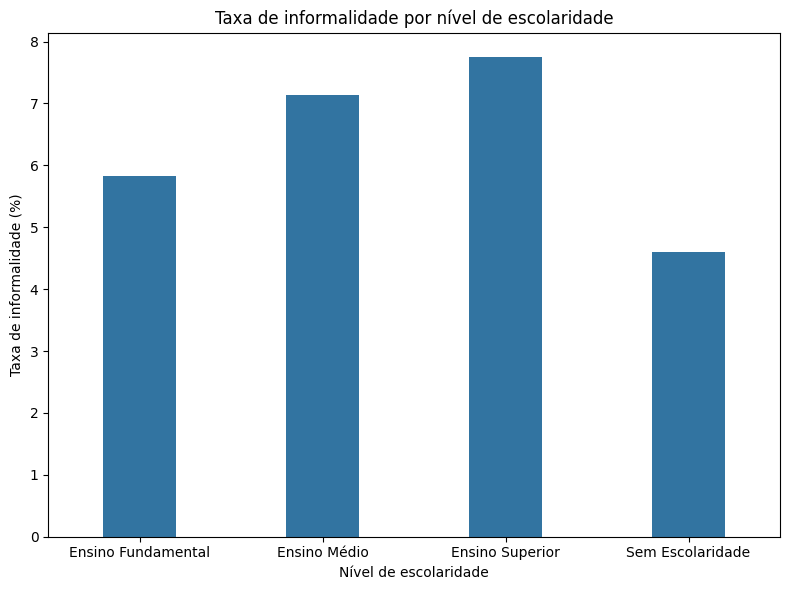

In [36]:
categorias_pergunta = ["Sem Escolaridade", "Ensino Fundamental", "Ensino Médio", "Ensino Superior"]
info_grafico = percentual_informais.reset_index()
info_grafico.columns = ["NIVEL_ESCOLARIDADE", "TAXA_INFORMALIDADE"]
info_grafico = info_grafico[info_grafico["NIVEL_ESCOLARIDADE"].isin(categorias_pergunta)]

mp.figure(figsize = (8, 6))
sb.barplot(data=info_grafico, x="NIVEL_ESCOLARIDADE" ,y="TAXA_INFORMALIDADE", width=0.4) #define-se aqui as medidas de cada eixo
mp.title("Taxa de informalidade por nível de escolaridade")
mp.xlabel("Nível de escolaridade")
mp.ylabel("Taxa de informalidade (%)")

mp.tight_layout()
mp.savefig("/content/drive/MyDrive/AmostraDS/graficos_relatorio/p2_escolaridade_trabalho.png", dpi=300)
mp.show()

## Pergunta 3

In [37]:
total_por_fx_etaria = df_pandas.groupby("FAIXA_ETARIA").size()
pcd_por_fx_etaria = df_pandas[df_pandas["CO_DEFICIENCIA_MEMB"] == 1].groupby("FAIXA_ETARIA")
qtd_pcd_por_fx_etaria = pcd_por_fx_etaria.size()

porcentagem_pcd_por_fx_etaria = (qtd_pcd_por_fx_etaria / total_por_fx_etaria) * 100

total_extrema_pobreza = (df_pandas[df_pandas["RENDA_PER_CAPITA"] <= 89].groupby("FAIXA_ETARIA"))
pcd_extrema_pobreza = (df_pandas[
    (df_pandas["CO_DEFICIENCIA_MEMB"] == 1) &
    (df_pandas["RENDA_PER_CAPITA"] <= 89)
].groupby("FAIXA_ETARIA"))

porcentagem_pcd_extrema_pobreza = ((pcd_extrema_pobreza.size()) / (qtd_pcd_por_fx_etaria)) * 100

resultado = pd.DataFrame({
    "Porcentagem_PCD_(%)" : porcentagem_pcd_por_fx_etaria,
    "Porcentagem_PCD_Extrema_Pobreza" : porcentagem_pcd_extrema_pobreza
}).reset_index()

print (resultado)

#OBS: As porcentagens não vão aparecer, pois a coluna com indicativos de PCD está vazia no dataset.



    FAIXA_ETARIA  Porcentagem_PCD_(%)  Porcentagem_PCD_Extrema_Pobreza
0    Adolescente                  NaN                              NaN
1         Adulto                  NaN                              NaN
2        Criança                  NaN                              NaN
3          Idoso                  NaN                              NaN
4          Jovem                  NaN                              NaN
5  Não declarado                  NaN                              NaN


## Pergunta 4

In [50]:
criancas_ate_6 = df_pandas[((df_pandas["IDADE"] >= 0) & (df_pandas["IDADE"] <= 6))]

#Identificamos quais crianças de até 6 anos são filhos do responsável familiar (de código 3)
filhos_do_rf = criancas_ate_6[criancas_ate_6["CO_PARENTESCO_RF_PESSOA"] == 3]

#Adquirimos todos os código familiares distintos. O 'unique' faz esse papel, removendo irmãos de mesma família, que poderiam prejudicar a análise das mães, por ex.
familias_com_criancas = filhos_do_rf["CO_FAMILIAR_FAM"].unique()

#Para identificar as mães, procuramos por mulheres("CO_SEXO_PESSOA" = 2), que sejam responsáveis familiares("CO_PARENTESCO_RF_PESSOA" = 1) e que sejam da mesma
#família que alguma das crianças (conferido pelo "CO_FAMILIAR_FAM")
maes_rf = df_pandas[(
    (df_pandas["CO_FAMILIAR_FAM"].isin(familias_com_criancas)) &
    (df_pandas["CO_PARENTESCO_RF_PESSOA"] == 1) &
    (df_pandas["CO_SEXO_PESSOA"] == 2)
)]

#Identificamos responsáveis familiares mulheres que não estejam no conjunto definido anteriormente de mães responsáveis familiares
m_rf_sem_criancas = df_pandas[(
    (df_pandas["CO_SEXO_PESSOA"] == 2) &
    (df_pandas["CO_PARENTESCO_RF_PESSOA"] == 1) &
    (~df_pandas["CO_CHV_NATURAL_PESSOA"].isin(maes_rf["CO_CHV_NATURAL_PESSOA"]))
)]

#Para a análise, foram consideradas tanto mães com empregos formais. Para tal, reaproveitou-se a Series previamente criada
#"CLASS_TRABALHO", que classifica 1 como informal e 2 como formal.
porcentagem_maes_rf = ((maes_rf["CLASS_TRABALHO"].isin([1, 2])).sum() / len(maes_rf)) * 100
porcentagem_m_rf_sem_criancas = ((m_rf_sem_criancas["CLASS_TRABALHO"].isin([1, 2])).sum() / len(m_rf_sem_criancas)) * 100

resultado = pd.DataFrame({
    "Grupo" : ["Com crianças", "Sem crianças"],
    "Porcentagem com renda de trabalho" : [porcentagem_maes_rf, porcentagem_m_rf_sem_criancas]
})

print (resultado)


          Grupo  Porcentagem com renda de trabalho
0  Com crianças                          41.186368
1  Sem crianças                          38.796843


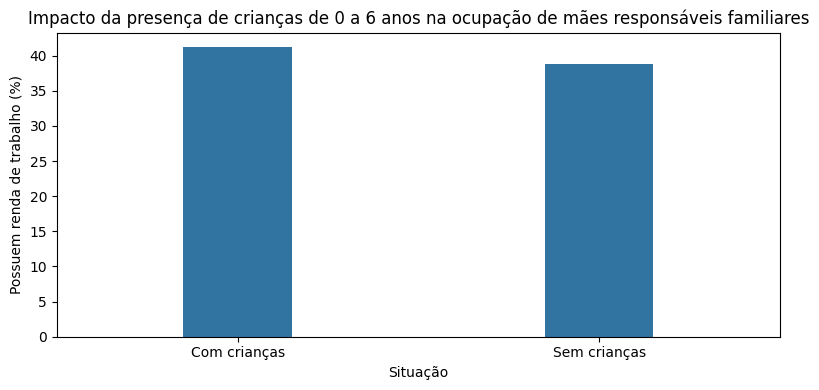

In [51]:
mp.figure(figsize = (8, 4))
sb.barplot(data=resultado, x="Grupo" ,y="Porcentagem com renda de trabalho", width=0.3) #define-se aqui as medidas de cada eixo
mp.title("Impacto da presença de crianças de 0 a 6 anos na ocupação de mães responsáveis familiares")
mp.xlabel("Situação")
mp.ylabel("Possuem renda de trabalho (%)")

mp.tight_layout()
mp.savefig("/content/drive/MyDrive/AmostraDS/graficos_relatorio/p4_ocupacao_maes.png", dpi=300, bbox_inches="tight")
mp.show()